# Delta Hedging: Where an Option Trader's P&L Really Comes From

**Goal.** Black-Scholes says a continuously hedged option has no risk. On a real desk,
hedging is discrete, costly, and done with a volatility that is only a guess. This project
simulates a trader who **sells a 6-month at-the-money call at 20% implied volatility**
and delta hedges it, to answer three questions:

1. How big is the hedging error when rebalancing is discrete?
2. What happens when realised volatility differs from the volatility sold?
3. With transaction costs, how often should the trader rebalance?

**Key idea.** A delta-hedged option is a bet on *realised vs implied volatility*:
$$d\text{P\&L} \approx \tfrac12\,\Gamma S^2\left(\sigma_{imp}^2\,dt - \left(\tfrac{dS}{S}\right)^2\right)$$
The seller earns theta when the stock moves less than implied, and loses on gamma when it moves more.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("hedging.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/06-delta-hedging")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hedging import simulate_paths, hedge_short_call, gamma_attribution, bs_call

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
S0, K, T, r, q, vol_implied, mu = 100.0, 100.0, 0.5, 0.03, 0.0, 0.20, 0.08
premium = bs_call(S0, K, T, r, q, vol_implied)
print(f"Premium received for the call: {premium:.3f} ({premium / S0:.2%} of spot)")

Premium received for the call: 6.371 (6.37% of spot)


## 1. Discrete hedging error

The stock is simulated under the **real-world** drift (8%), not the risk-free rate: the
hedge removes the drift, which is why option prices do not depend on it. With realised
volatility equal to implied, the P&L is centred on zero and its standard deviation falls
like $1/\sqrt{N}$ in the number of rebalancings $N$.

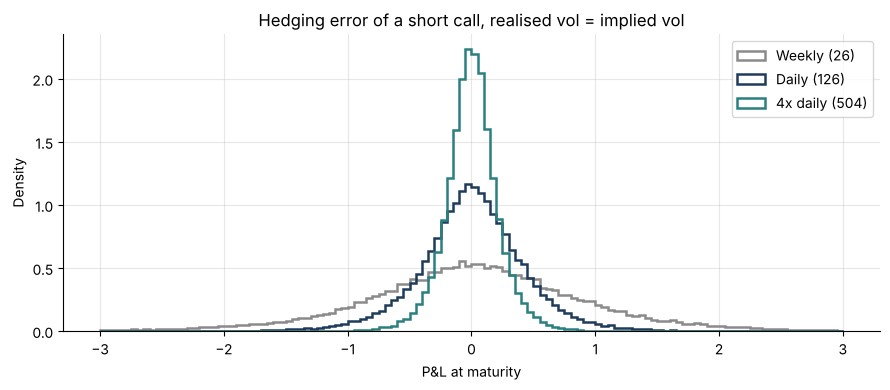

,Mean P&L,Std P&L,Std / premium
Rebalancing,,,
Weekly (26),0.0026,0.9231,0.1449
Daily (126),0.0006,0.4307,0.0676
4x daily (504),0.0006,0.2153,0.0338


In [2]:
freqs = {"Weekly (26)": 26, "Daily (126)": 126, "4x daily (504)": 504}
fig, ax = plt.subplots(figsize=(9, 4))
rows = []
for (label, n), c in zip(freqs.items(), [GREY, NAVY, TEAL]):
    x = hedge_short_call(simulate_paths(S0, mu, q, vol_implied, T, n, 50_000, seed=1), K, T, r, q, vol_implied)
    ax.hist(x, bins=120, range=(-3, 3), density=True, histtype="step", lw=1.8, color=c, label=label)
    rows.append({"Rebalancing": label, "Mean P&L": x.mean(), "Std P&L": x.std(), "Std / premium": x.std() / premium})
ax.set(xlabel="P&L at maturity", ylabel="Density", title="Hedging error of a short call, realised vol = implied vol")
ax.legend(); plt.tight_layout(); plt.savefig("images/hedging_error.png", dpi=150); plt.show()
pd.DataFrame(rows).set_index("Rebalancing").round(4)

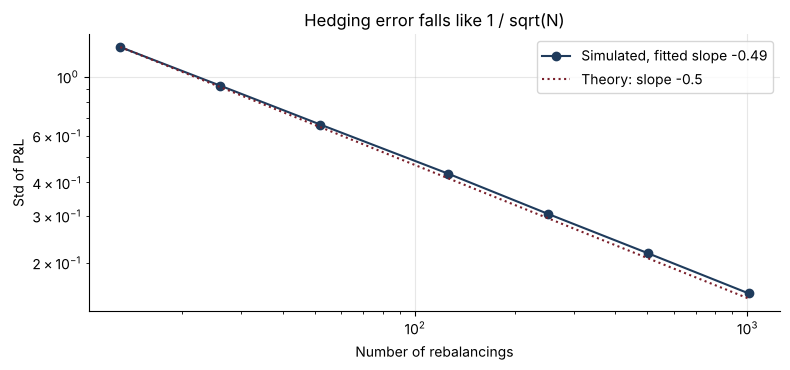

In [3]:
ns = np.array([13, 26, 52, 126, 252, 504, 1008])
stds = [hedge_short_call(simulate_paths(S0, mu, q, vol_implied, T, n, 20_000, seed=2), K, T, r, q, vol_implied).std() for n in ns]
slope = np.polyfit(np.log(ns), np.log(stds), 1)[0]
plt.figure(figsize=(8, 3.8))
plt.loglog(ns, stds, "o-", color=NAVY, label=f"Simulated, fitted slope {slope:.2f}")
plt.loglog(ns, stds[0] * np.sqrt(ns[0] / ns), ":", color=BORDEAUX, label="Theory: slope -0.5")
plt.xlabel("Number of rebalancings"); plt.ylabel("Std of P&L"); plt.legend()
plt.title("Hedging error falls like 1 / sqrt(N)"); plt.tight_layout(); plt.savefig("images/convergence.png", dpi=150); plt.show()

## 2. Selling volatility too cheap

Now the stock realises **25%** while the trader sold at 20%. Two ways to hedge:

- **Hedge at implied (20%)**: the P&L depends on the path, through where gamma was large
  when the stock moved.
- **Hedge at realised (25%)**: the loss is locked in at $BS(20\%) - BS(25\%)$, whatever the path.

Both lose on average, since the option was sold too cheap, but the risk profile differs.

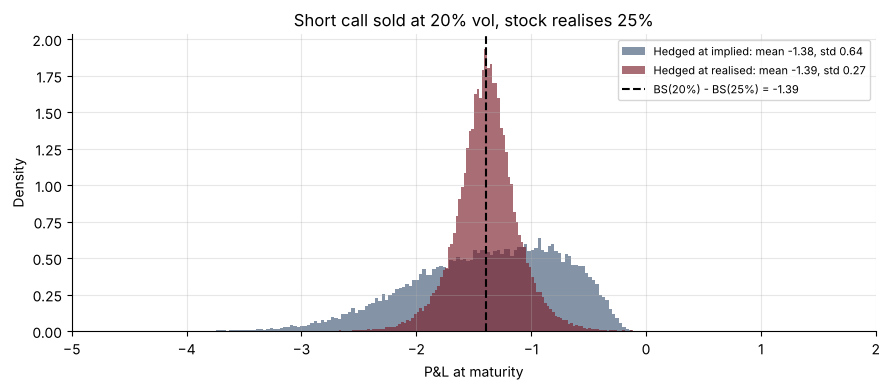

In [4]:
paths = simulate_paths(S0, mu, q, 0.25, T, 504, 40_000, seed=3)
at_implied = hedge_short_call(paths, K, T, r, q, vol_implied)
at_realised = hedge_short_call(paths, K, T, r, q, vol_implied, sigma_hedge=0.25)
locked = bs_call(S0, K, T, r, q, vol_implied) - bs_call(S0, K, T, r, q, 0.25)
plt.figure(figsize=(9, 4))
plt.hist(at_implied, bins=150, density=True, color=NAVY, alpha=0.55, label=f"Hedged at implied: mean {at_implied.mean():.2f}, std {at_implied.std():.2f}")
plt.hist(at_realised, bins=150, density=True, color=BORDEAUX, alpha=0.65, label=f"Hedged at realised: mean {at_realised.mean():.2f}, std {at_realised.std():.2f}")
plt.axvline(locked, color="black", ls="--", label=f"BS(20%) - BS(25%) = {locked:.2f}")
plt.xlim(-5, 2); plt.xlabel("P&L at maturity"); plt.ylabel("Density"); plt.legend(fontsize=8)
plt.title("Short call sold at 20% vol, stock realises 25%")
plt.tight_layout(); plt.savefig("images/vol_mismatch.png", dpi=150); plt.show()

## 3. Gamma-theta attribution

Summing $\tfrac12\Gamma S^2(\sigma_{imp}^2\,dt - r_t^2)$ step by step reproduces the
simulated P&L almost exactly. This is how a desk explains its daily P&L: realised moves
against the implied volatility, weighted by gamma.

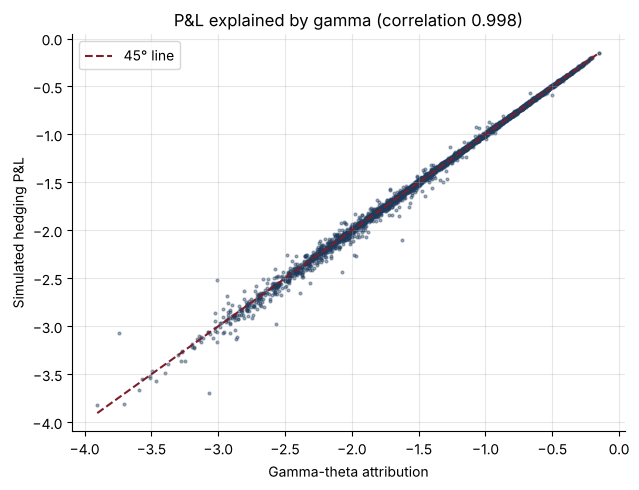

In [5]:
sub = paths[:4000]
approx = gamma_attribution(sub, K, T, r, q, vol_implied)
actual = at_implied[:4000]
plt.figure(figsize=(6.5, 5))
plt.scatter(approx, actual, s=4, alpha=0.4, color=NAVY)
lims = [min(approx.min(), actual.min()), max(approx.max(), actual.max())]
plt.plot(lims, lims, color=BORDEAUX, ls="--", label="45° line")
plt.xlabel("Gamma-theta attribution"); plt.ylabel("Simulated hedging P&L")
plt.title(f"P&L explained by gamma (correlation {np.corrcoef(approx, actual)[0, 1]:.3f})"); plt.legend()
plt.tight_layout(); plt.savefig("images/attribution.png", dpi=150); plt.show()

## 4. Transaction costs: how often to rebalance?

Each rebalancing costs 10 bp of the traded value. Rebalancing more reduces the hedging
noise but increases the cost: there is an optimal frequency. A simple risk-adjusted
criterion is to minimise **expected cost + 2 × standard deviation**.

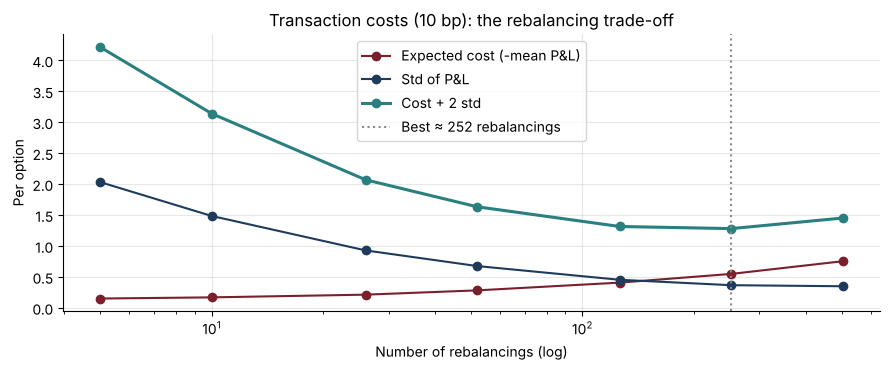

,Mean P&L,Std P&L,Cost + 2 std
Rebalancings,,,
5,-0.150,2.033,4.216
10,-0.169,1.485,3.140
26,-0.213,0.929,2.070
52,-0.283,0.676,1.634
126,-0.408,0.454,1.315
252,-0.549,0.366,1.281
504,-0.754,0.349,1.452


In [6]:
ns = np.array([5, 10, 26, 52, 126, 252, 504])
res = []
for n in ns:
    x = hedge_short_call(simulate_paths(S0, mu, q, vol_implied, T, n, 20_000, seed=4), K, T, r, q, vol_implied, tx_cost=0.001)
    res.append({"Rebalancings": n, "Mean P&L": x.mean(), "Std P&L": x.std(), "Cost + 2 std": -x.mean() + 2 * x.std()})
tc = pd.DataFrame(res).set_index("Rebalancings")
best = tc["Cost + 2 std"].idxmin()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(tc.index, -tc["Mean P&L"], "o-", color=BORDEAUX, label="Expected cost (-mean P&L)")
ax.plot(tc.index, tc["Std P&L"], "o-", color=NAVY, label="Std of P&L")
ax.plot(tc.index, tc["Cost + 2 std"], "o-", color=TEAL, lw=2.2, label="Cost + 2 std")
ax.axvline(best, color=GREY, ls=":", label=f"Best ≈ {best} rebalancings")
ax.set_xscale("log"); ax.set(xlabel="Number of rebalancings (log)", ylabel="Per option"); ax.legend()
ax.set_title("Transaction costs (10 bp): the rebalancing trade-off")
plt.tight_layout(); plt.savefig("images/transaction_costs.png", dpi=150); plt.show()
tc.round(3)

## Conclusions
- Discrete hedging leaves a noise that falls like $1/\sqrt{N}$ (fitted slope about −0.5):
  daily hedging of a 6-month ATM call still leaves a standard deviation of about 0.4.
- A delta-hedged option is a volatility trade: selling at 20% when the stock realises 25%
  loses about 1.4 per option, and the gamma-theta attribution explains the P&L path by path.
- With 10 bp costs, the optimum is finite: here about 250 rebalancings over 6 months
  (twice a day); hedging more often adds more cost than it removes risk.
- **Next steps:** Leland's volatility adjustment, hedging bands (Whalley-Wilmott), and
  vega hedging with a second option.